# NimbusPay ticket triage: QLoRA fine-tune of Qwen2.5-3B-Instruct

Runs top to bottom on a free Colab **T4**.

* **Model:** `Qwen/Qwen2.5-3B-Instruct` (3.1B params). It has a native system role and its own chat template.
* **Method:** QLoRA (4-bit NF4 base model + LoRA r=16 on all linear layers, about 30M trainable params).
* **Stack:** Hugging Face `transformers` + `peft` + `bitsandbytes`, with the plain `Trainer`. I chose it because every step is visible and easy to explain: the template, the loss mask and the collator are all written out below.

Flow: **A** audit and clean → **B** baselines → **C** training pipeline → **D** experiments → final model and test predictions → **E** error analysis.

Set `RUN_ABLATIONS = False` to only reproduce the final model and predictions, which takes about 1.5 h. Results of runs that already finished are cached on Drive and skipped.

In [1]:
!pip -q install transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 "bitsandbytes>=0.48"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'   # less GPU memory fragmentation
from google.colab import drive
drive.mount('/content/drive')
import glob
# find the uploaded 'vima3ya_colab' folder anywhere in the top levels of My Drive
found = sorted(glob.glob('/content/drive/MyDrive/vima3ya_colab') + glob.glob('/content/drive/MyDrive/*/vima3ya_colab')
               + glob.glob('/content/drive/MyDrive/*/*/vima3ya_colab'))
assert found, "Could not find a folder named 'vima3ya_colab' in your Google Drive"
BASE = found[0]   # holds data/, SCHEMA.md, score.py, rules.py, clean.py, augment.py
print('Using folder:', BASE)
%cd {BASE}
!mkdir -p adapters preds results
!nvidia-smi --query-gpu=name,memory.total --format=csv

RUN_ABLATIONS = True        # False = only baselines' cache + final model + predictions

Mounted at /content/drive
Using folder: /content/drive/MyDrive/VIMA3YA/vima3ya_colab
/content/drive/MyDrive/VIMA3YA/vima3ya_colab
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Part A: Audit and clean the training data

How each problem was found: every check below is a rule taken straight from `SCHEMA.md`. I run the **same checks on dev**, which is clean by definition, to show they only flag real problems: dev gets zero on all of them.

In [4]:
import json, re, collections
import pandas as pd
import rules, clean
from score import score, load, KEYS

train_raw = load('data/train.jsonl'); dev = load('data/dev.jsonl'); test = load('data/test_inputs.jsonl')

def audit(rows, held_out=()):
    held = {clean.norm(r['messages'][1]['content']) for r in held_out}
    issues, seen = collections.Counter(), set()
    for r in rows:
        u, a = r['messages'][1]['content'], r['messages'][-1]['content']
        k, t = clean.norm(u), rules.body(u)
        issues['junk text (test/asdf/empty)'] += t.strip().lower() in clean.JUNK
        issues['leak: same ticket in dev/test'] += k in held
        issues['duplicate ticket'] += k in seen
        seen.add(k)
        try:
            lab = json.loads(a)
        except json.JSONDecodeError:
            issues['truncated / invalid JSON label'] += 1; continue
        if 'prio' in lab:
            issues["old spec: key 'prio', values high/medium/low, DD/MM/YYYY dates"] += 1; continue
        cat, amt = lab['category'], lab['amount_paise']
        issues['priority breaks the P1/P2/P3 rules'] += lab['priority'] != rules.priority(cat, amt, t)
        issues['needs_human breaks the rule'] += lab['needs_human'] != rules.needs_human(rules.priority(cat, amt, t), t)
        issues['amount in rupees, not paise'] += amt is not None and amt not in clean.amounts_in(t)
        if cat in clean.TXN_CATS:
            d = rules.find_date(u)
            issues['txn_date wrong (vs date in text)'] += (d.isoformat() if d else None) != lab['txn_date']
            issues['txn_id not normalised / wrong'] += rules.txn_id(u) != lab['txn_id']
        else:
            issues['txn fields not null for non-txn category'] += any(lab[x] is not None for x in ('amount_paise', 'txn_date', 'txn_id', 'channel'))
    return pd.Series(issues)

pd.DataFrame({'train': audit(train_raw, dev + test), 'dev (control)': audit(dev)}).fillna(0).astype(int)

,train,dev (control)
"amount in rupees, not paise",32,0
duplicate ticket,100,0
junk text (test/asdf/empty),10,0
leak: same ticket in dev/test,45,0
needs_human breaks the rule,4,0
"old spec: key 'prio', values high/medium/low, DD/MM/YYYY dates",70,0
priority breaks the P1/P2/P3 rules,65,0
truncated / invalid JSON label,25,0
txn fields not null for non-txn category,0,0
txn_date wrong (vs date in text),4,0


Decision per problem: **drop** junk, leaked, duplicate and truncated rows, since a correct label cannot be recovered safely. **Fix** everything else by re-applying the `SCHEMA.md` rules (`clean.py`). The fixer is checked on dev: it changes **0 of 200** dev labels.

In [5]:
!python clean.py
log = pd.read_csv('cleaning_log.csv')
print(log.action.value_counts().to_string())
kinds = log.reason.str.split('; ').explode().str.extract(r'^([a-z_]+)', expand=False)
print(kinds.value_counts().to_string())

# sanity: the fixer leaves every clean dev label unchanged
changed = sum(clean.fix_label(json.loads(r['messages'][2]['content']), r['messages'][1]['content'])[1] != [] for r in dev)
print('dev labels changed by the fixer:', changed)

kept 1265 / 1445 rows; dropped 180, fixed 175
action
drop    180
fix     175
reason
priority     130
duplicate    100
old           70
same          45
txn_date      30
amount        25
label         25
txn_id        20
junk          10
dev labels changed by the fixer: 0


In [6]:
# Experiment 4 data: label-preserving "hard surface form" copies (see augment.py)
!python augment.py
# Experiment 1 data: raw train, minus only the rows that leak dev/test tickets (training on those would be training on dev)
held = {clean.norm(r['messages'][1]['content']) for r in dev + test}
with open('data/train_raw_noleak.jsonl', 'w', encoding='utf-8') as f:
    for r in train_raw:
        if clean.norm(r['messages'][1]['content']) not in held:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
!wc -l data/train_raw_noleak.jsonl data/train_clean.jsonl data/train_aug.jsonl

1265 clean rows + 835 augmented = 2100
   1400 data/train_raw_noleak.jsonl
   1265 data/train_clean.jsonl
   2100 data/train_aug.jsonl
   4765 total


## Part C: Model, chat template, loss masking, sequence length

In [7]:
import time, gc, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, TrainingArguments, Trainer, set_seed
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
tok = AutoTokenizer.from_pretrained(MODEL_ID)

def encode(r):
    # prompt = system + user, formatted by the model's own chat template, ending in '<|im_start|>assistant\n'
    prompt = tok.apply_chat_template(r['messages'][:2], add_generation_prompt=True)
    # answer = the JSON label + end-of-turn token, so the model learns to stop
    answer = tok(r['messages'][2]['content'] + '<|im_end|>', add_special_tokens=False)['input_ids']
    # loss only on the answer tokens: prompt positions get label -100 (ignored by the loss)
    return {'input_ids': prompt + answer, 'labels': [-100] * len(prompt) + answer}

ex = encode(load('data/train_clean.jsonl')[0])
print('FULL INPUT:\n' + tok.decode(ex['input_ids']))
print('\nTOKENS WITH LOSS:\n' + tok.decode([t for t, l in zip(ex['input_ids'], ex['labels']) if l != -100]))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

FULL INPUT:
<|im_start|>system
You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.<|im_end|>
<|im_start|>user
Received: 2026-07-25 (Sat)
Source: app-chat

Hi, I have a top up that didn't go through. Why? It was today. Mode: internet banking. My phone is a Redmi Note 12. It is 4.7k in total. My account balance is 258 rupees right now. The txn id is NP1599046332. Waiting for your reply.<|im_end|>
<|im_start|>assistant
{"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}<|im_end|>

TOKENS WITH LOSS:
{"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}<|im_end|>


In [8]:
import numpy as np
for f in ['data/train_clean.jsonl', 'data/train_aug.jsonl', 'data/dev.jsonl']:
    L = np.array([len(encode(r)['input_ids']) for r in load(f)])
    print(f'{f:26} p50={np.percentile(L,50):.0f} p95={np.percentile(L,95):.0f} p99={np.percentile(L,99):.0f} max={L.max()}')
L = [len(tok.apply_chat_template(r['messages'][:2], add_generation_prompt=True)) for r in test]
print('test prompt max', max(L))
A = [len(tok(r['messages'][2]['content'])['input_ids']) for r in dev]
print('longest gold JSON answer (tokens):', max(A), '-> max_new_tokens=200 is plenty')

# 95% of tickets are < 250 tokens, but long email threads with quoted replies reach ~2.3k tokens.
# Those are exactly the cases where the model must learn to IGNORE quoted dates, so I keep them
# instead of truncating: MAX_LEN covers the longest example, so nothing is cut.
MAX_LEN = 2304

data/train_clean.jsonl     p50=167 p95=225 p99=1858 max=2214
data/train_aug.jsonl       p50=180 p95=248 p99=1937 max=2255
data/dev.jsonl             p50=172 p95=222 p99=1516 max=2180
test prompt max 2089
longest gold JSON answer (tokens): 81 -> max_new_tokens=200 is plenty


In [9]:
def collate(batch):                       # right-pad a batch; padded label positions are ignored
    n = max(len(b['input_ids']) for b in batch)
    pad = lambda x, v: x + [v] * (n - len(x))
    return {'input_ids': torch.tensor([pad(b['input_ids'], tok.pad_token_id) for b in batch]),
            'labels': torch.tensor([pad(b['labels'], -100) for b in batch]),
            'attention_mask': torch.tensor([pad([1] * len(b['input_ids']), 0) for b in batch])}

def load_base(four_bit=True):
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float16) if four_bit else None
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=q, torch_dtype=torch.float16, device_map={'': 0})

@torch.no_grad()
def generate(model, rows, bs=8, system=None):
    # Exactly the required inference: system + user through the chat template, plain greedy generate,
    # max_new_tokens=200, output stripped of whitespace and nothing else.
    tok.padding_side = 'left'
    model.eval()
    prompts = []
    for r in rows:
        msgs = [dict(m) for m in r['messages'][:2]]
        if system: msgs[0]['content'] = system            # only used by the rules-in-prompt baseline
        prompts.append(tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False))
    order = sorted(range(len(rows)), key=lambda i: len(prompts[i]))   # similar lengths together = less padding
    outs = [None] * len(rows)
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        enc = tok([prompts[i] for i in idx], return_tensors='pt', padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=200, do_sample=False)
        for i, g in zip(idx, gen):
            outs[i] = tok.decode(g[enc['input_ids'].shape[1]:], skip_special_tokens=True).strip()
    return [{'id': r['id'], 'output': o} for r, o in zip(rows, outs)]

def save_jsonl(rows, path):
    with open(path, 'w', encoding='utf-8') as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + '\n')

def dev_score(preds):
    s = score(dev, preds)['all']
    return {'exact_match': round(s['exact_match'], 4), 'mean_field_acc': round(s['mean_field_acc'], 4),
            'json_valid': s['json_valid'], **{f'acc_{k}': round(v, 3) for k, v in s['fields'].items()}}

def free():                               # call after `del model` to give the GPU memory back
    gc.collect(); torch.cuda.empty_cache()

## Part B: Baselines (no fine-tuning)

1. The base model with the fixed prompt.
2. The base model with the full `SCHEMA.md` rules added to the system prompt. This is allowed here only, as a reference point.

In [10]:
import os
def cached(name):
    p = f'results/{name}.json'
    return json.load(open(p)) if os.path.exists(p) else None

if not (cached('baseline_zero_shot') and cached('baseline_rules_in_prompt')):
    model = load_base(True)
    schema = open('SCHEMA.md', encoding='utf-8').read()
    for name, system in [('baseline_zero_shot', None),
                         ('baseline_rules_in_prompt', dev[0]['messages'][0]['content'] + '\n\n' + schema)]:
        torch.cuda.reset_peak_memory_stats()
        preds = generate(model, dev, bs=4, system=system)
        save_jsonl(preds, f'preds/dev_{name}.jsonl')
        res = {'name': name, 'change': 'no fine-tuning', **dev_score(preds),
               'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 2**30, 2), 'train_min': 0}
        json.dump(res, open(f'results/{name}.json', 'w'))
        print(res)
        print('example output:', preds[0]['output'][:300])
    del model; free()

## Training function

Main settings and why:

| Setting | Value | Why |
|---|---|---|
| Base model | Qwen2.5-3B-Instruct, 4-bit NF4 + double quant | Strongest instruct model ≤ 4B that fits a T4 with room for 2.3k-token examples; native system role |
| LoRA | r=16, alpha=32, dropout 0.05, all 7 linear layers | About 30M trainable params, under the 50M limit. All-linear LoRA learns format and rules better than attention-only |
| LR | 2e-4, cosine, 10 warm-up steps | Standard QLoRA learning rate. Cosine decay settles the strict output format |
| Batch | 2 × grad-accum 8 = 16 | Batch 2 keeps the long 2.3k-token threads within T4 memory (16-bit LoRA needs 1 × 16: same effective batch) |
| Epochs | 2 | Small templated dataset. Experiment 3 tests 1 epoch |
| Max length | 2304 | Covers the longest example (see above), so nothing is truncated |
| fp16, paged 8-bit AdamW, gradient checkpointing | | The T4 has no bf16; these settings save memory |
| `group_by_length` | | Batches tickets of similar length, so there's less padding and training is faster |

In [11]:
def run(name, train_file, four_bit=True, r=16, epochs=2, lr=2e-4, bs=2, change=''):
    if cached(name):
        print('cached:', name); return cached(name)
    set_seed(42)
    rows = [encode(x) for x in load(train_file)]
    rows = [x for x in rows if len(x['input_ids']) <= MAX_LEN]
    torch.cuda.reset_peak_memory_stats()
    model = load_base(four_bit)
    if four_bit:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                gradient_checkpointing_kwargs={'use_reentrant': False})
    else:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
        model.enable_input_require_grads()
    lora = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, task_type='CAUSAL_LM',
                      target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'])
    model = get_peft_model(model, lora)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n_train <= 50e6, n_train
    print(f'{name}: {len(rows)} train rows, {n_train/1e6:.1f}M trainable params')
    args = TrainingArguments(output_dir=f'/content/runs/{name}', per_device_train_batch_size=bs, gradient_accumulation_steps=16 // bs,
                             num_train_epochs=epochs, learning_rate=lr, lr_scheduler_type='cosine', warmup_steps=10,
                             logging_steps=10, save_strategy='no', fp16=True, optim='paged_adamw_8bit',
                             group_by_length=True, report_to='none', remove_unused_columns=False, seed=42)
    t0 = time.time()
    trainer = Trainer(model=model, args=args, train_dataset=rows, data_collator=collate)
    trainer.train()
    minutes = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 2**30
    model.save_pretrained(f'adapters/{name}')
    losses = [h['loss'] for h in trainer.state.log_history if 'loss' in h]
    del trainer, model; free()

    # evaluate exactly like the graders: fresh base model + saved adapter
    model = PeftModel.from_pretrained(load_base(four_bit), f'adapters/{name}')
    preds = generate(model, dev)
    save_jsonl(preds, f'preds/dev_{name}.jsonl')
    del model; free()
    res = {'name': name, 'change': change, **dev_score(preds), 'peak_gpu_gb': round(peak, 2),
           'train_min': round(minutes, 1), 'trainable_M': round(n_train / 1e6, 1), 'train_rows': len(rows), 'loss_curve': losses}
    json.dump(res, open(f'results/{name}.json', 'w'))
    print({k: v for k, v in res.items() if k != 'loss_curve'})
    return res

## Part D: Controlled experiments (one change at a time)

Reference config `clean_qlora`: cleaned data, 4-bit QLoRA, r=16, 2 epochs, lr 2e-4. Each experiment changes exactly one thing relative to it.

1. **Data:** raw (only dev/test leaks removed) vs cleaned.
2. **Precision:** 16-bit LoRA (fp16 base) vs 4-bit QLoRA.
3. **Epochs:** 1 vs 2.
4. **My idea:** add label-preserving "hard surface form" copies of transaction tickets. Ids and amounts are rewritten in other valid formats, and distracting balance/limit amounts and quoted e-mails with their own dates are added (`augment.py`). The test set is said to be harder than dev, and these are exactly the traps that `SCHEMA.md` describes.

In [12]:
EXPERIMENTS = [
    dict(name='clean_qlora',  train_file='data/train_clean.jsonl',      change='reference: clean data, QLoRA 4-bit, r16, 2 ep'),
    dict(name='raw_qlora',    train_file='data/train_raw_noleak.jsonl', change='(1) raw data instead of cleaned'),
    dict(name='clean_lora16', train_file='data/train_clean.jsonl',      change='(2) 16-bit LoRA instead of 4-bit QLoRA', four_bit=False, bs=1),   # bs 1 x accum 16: same effective batch, fits in memory
    dict(name='clean_1ep',    train_file='data/train_clean.jsonl',      change='(3) 1 epoch instead of 2', epochs=1),
    dict(name='aug_qlora',    train_file='data/train_aug.jsonl',        change='(4) + hard surface-form augmentation'),
]
FINAL = 'aug_qlora'      # set to the best experiment on dev after the runs below

for e in EXPERIMENTS:
    if RUN_ABLATIONS or e['name'] == FINAL:
        run(**e)

cached: clean_qlora
cached: raw_qlora
cached: clean_lora16
cached: clean_1ep
cached: aug_qlora


In [13]:
names = ['baseline_zero_shot', 'baseline_rules_in_prompt'] + [e['name'] for e in EXPERIMENTS]
table = pd.DataFrame([cached(n) for n in names if cached(n)])
cols = ['name', 'change', 'exact_match', 'mean_field_acc', 'peak_gpu_gb', 'train_min']
display(table[cols])
display(table[['name'] + [c for c in table.columns if c.startswith('acc_')]])

,name,change,exact_match,mean_field_acc,peak_gpu_gb,train_min
0,baseline_zero_shot,no fine-tuning,0.000,0.0006,2.90,0.0
1,baseline_rules_in_prompt,no fine-tuning,0.120,0.7788,3.55,0.0
2,clean_qlora,"reference: clean data, QLoRA 4-bit, r16, 2 ep",0.885,0.9788,12.03,23.1
3,raw_qlora,(1) raw data instead of cleaned,0.880,0.9788,12.03,24.7
4,clean_lora16,(2) 16-bit LoRA instead of 4-bit QLoRA,0.845,0.9700,10.02,27.0
5,clean_1ep,(3) 1 epoch instead of 2,0.565,0.9219,12.02,11.3
6,aug_qlora,(4) + hard surface-form augmentation,0.935,0.9881,12.20,39.3


,name,acc_category,acc_priority,acc_amount_paise,acc_txn_date,acc_txn_id,acc_channel,acc_language,acc_needs_human
0,baseline_zero_shot,0.005,0.000,0.0,0.000,0.000,0.000,0.000,0.000
1,baseline_rules_in_prompt,0.815,0.355,0.9,0.830,0.805,0.900,0.905,0.720
2,clean_qlora,0.985,0.925,1.0,0.970,0.995,1.000,1.000,0.955
3,raw_qlora,0.975,0.930,1.0,0.965,0.995,1.000,1.000,0.965
4,clean_lora16,0.975,0.890,1.0,0.975,1.000,0.995,1.000,0.925
5,clean_1ep,0.955,0.635,1.0,0.960,1.000,0.995,1.000,0.830
6,aug_qlora,0.995,0.955,1.0,0.980,1.000,1.000,1.000,0.975


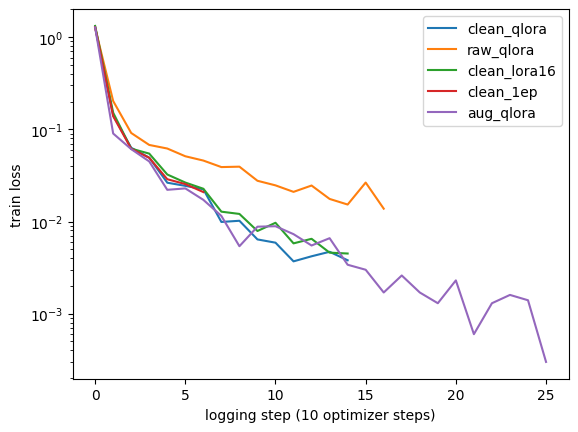

In [14]:
import matplotlib.pyplot as plt
for n in names:
    r = cached(n)
    if r and r.get('loss_curve'): plt.plot(r['loss_curve'], label=n)
plt.xlabel('logging step (10 optimizer steps)'); plt.ylabel('train loss'); plt.yscale('log'); plt.legend(); plt.show()

## Final model and test predictions

The final adapter is `adapters/{FINAL}`. Test predictions are generated **one ticket at a time** (batch size 1, no padding), exactly as a grader would regenerate them.

In [15]:
model = PeftModel.from_pretrained(load_base(True), f'adapters/{FINAL}')
t0 = time.time()
test_preds = generate(model, test, bs=1)
save_jsonl(test_preds, 'predictions_test.jsonl')
print(f'{len(test_preds)} test predictions in {(time.time()-t0)/60:.1f} min')
from score import parse
print('valid JSON:', sum(parse(p['output']) is not None for p in test_preds), '/', len(test_preds))
print(test_preds[0])
del model; free()

# copy the final adapter to ./adapter for the submission
!rm -rf adapter && cp -r adapters/{FINAL} adapter && ls -la adapter

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


400 test predictions in 55.0 min
valid JSON: 400 / 400
{'id': 'ts-00001', 'output': '{"category": "fraud", "priority": "P1", "amount_paise": null, "txn_date": "2026-06-30", "txn_id": "NP6090913363", "channel": null, "language": "hi-en", "needs_human": true}'}
total 117008
drwx------ 2 root root      4096 Oct 29 07:10 .
drwx------ 8 root root      4096 Oct 29 07:10 ..
-rw------- 1 root root       857 Oct 29 07:10 adapter_config.json
-rw------- 1 root root 119801528 Oct 29 07:10 adapter_model.safetensors
-rw------- 1 root root      5098 Oct 29 07:10 README.md


In [16]:
# reproducibility check: reload from ./adapter and regenerate a random sample, must match the file
import random
random.seed(0)
sample = random.sample(test, 10)
model2 = PeftModel.from_pretrained(load_base(True), 'adapter')
again = {p['id']: p['output'] for p in generate(model2, sample, bs=1)}
saved = {p['id']: p['output'] for p in test_preds}
print('matches:', sum(again[i] == saved[i] for i in again), '/', len(again))
del model2; free()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

matches: 10 / 10


## Part E: Error analysis (best model on dev)

In [17]:
!python score.py --gold data/dev.jsonl --pred preds/dev_{FINAL}.jsonl

group                            n   valid   exact  fields
all                            200  100.0%   93.5%   98.8%
category=account_access         19  100.0%  100.0%  100.0%
category=fraud                  15  100.0%   93.3%   99.2%
category=kyc                    24  100.0%  100.0%  100.0%
category=offers                 18  100.0%  100.0%  100.0%
category=other                  16  100.0%   93.8%   98.4%
category=payment_failed         53  100.0%   88.7%   98.1%
category=refund                 55  100.0%   90.9%   98.2%

per-field accuracy (all rows)
  category        99.5%
  priority        95.5%
  amount_paise   100.0%
  txn_date        98.0%
  txn_id         100.0%
  channel        100.0%
  language       100.0%
  needs_human     97.5%


In [18]:
from score import parse
preds = {p['id']: p['output'] for p in load(f'preds/dev_{FINAL}.jsonl')}
fails = []
for g in dev:
    gold = json.loads(g['messages'][2]['content'])
    pred = parse(preds[g['id']]) or {}
    for k in KEYS:
        if not (k in pred and type(pred[k]) is type(gold[k]) and pred[k] == gold[k]):
            fails.append({'id': g['id'], 'category': gold['category'], 'field': k, 'gold': gold[k],
                          'pred': pred.get(k, 'MISSING'), 'ticket': rules.body(g['messages'][1]['content'])[:220],
                          'received': g['messages'][1]['content'][10:26]})
fails = pd.DataFrame(fails)
print('wrong fields by field:'); print(fails.field.value_counts().to_string())
print('\nwrong fields by gold category:'); print(fails.category.value_counts().to_string())
pred_cat = [ (parse(preds[g['id']]) or {}).get('category') for g in dev]
gold_cat = [json.loads(g['messages'][2]['content'])['category'] for g in dev]
display(pd.crosstab(pd.Series(gold_cat, name='gold'), pd.Series(pred_cat, name='pred')))

wrong fields by field:
field
priority       9
needs_human    5
txn_date       4
category       1

wrong fields by gold category:
category
refund            8
payment_failed    8
other             2
fraud             1


pred,account_access,fraud,kyc,offers,other,payment_failed,refund
gold,,,,,,,
account_access,19,0,0,0,0,0,0
fraud,0,15,0,0,0,0,0
kyc,0,0,24,0,0,0,0
offers,0,0,0,18,0,0,0
other,1,0,0,0,15,0,0
payment_failed,0,0,0,0,0,53,0
refund,0,0,0,0,0,0,55


In [19]:
pd.set_option('display.max_colwidth', 220)
display(fails.sort_values(['field', 'id']).head(40))

,id,category,field,gold,pred,ticket,received
8,dv-00084,other,category,other,account_access,"Dear NimbusPay support, I didn't get a PIN yet. What gives? I am on the iOS app. Please look into it.",2026-08-07 (Fri)
2,dv-00011,refund,needs_human,True,False,"Subject: Problem with NimbusPay\n\nURGENT!!\nWhy am I missing my refund. App version is 4.2.7. ₹84,137 was the value. This happened yesterday. ID: np3333133441\n\nRegards,\nPooja Nair",2026-06-17 (Wed)
4,dv-00034,payment_failed,needs_human,False,True,@NimbusPayCare Shopping ka payment decline ho gaya lekin bank ne paise kaat liye. Rs. 36737 ka transaction tha. Txn id np 94424 25625. Wallet se hua tha.,2026-08-22 (Sat)
7,dv-00056,refund,needs_human,False,True,"Why was I double charged? Using the Android app. That was yesterday. It is Rs 44,206.75 in total. Please look into it.",2026-08-29 (Sat)
12,dv-00098,refund,needs_human,False,True,"[IVR transcript] Hi team, I have a duplicate payment showing up on the app. How do I stop myself being charged for the thing twice? It was from the NimbusPay wallet. That was today. My account balance is ₹1,871 right...",2026-06-08 (Mon)
16,dv-00129,payment_failed,needs_human,False,True,"Subject: Complaint\n\nHello,\nThe app denied my topped up. Amount: Rs. 49657 My phone is a Realme 11. Transaction date Jul 29.\n\nRegards,\nArjun Das",2026-07-31 (Fri)
1,dv-00011,refund,priority,P1,P2,"Subject: Problem with NimbusPay\n\nURGENT!!\nWhy am I missing my refund. App version is 4.2.7. ₹84,137 was the value. This happened yesterday. ID: np3333133441\n\nRegards,\nPooja Nair",2026-06-17 (Wed)
3,dv-00034,payment_failed,priority,P2,P1,@NimbusPayCare Shopping ka payment decline ho gaya lekin bank ne paise kaat liye. Rs. 36737 ka transaction tha. Txn id np 94424 25625. Wallet se hua tha.,2026-08-22 (Sat)
5,dv-00044,refund,priority,P2,P3,I can't see my refund in my history. Amount: Rs. 8377 Mode: debit card. You can check NP 1458501327. Dated 27/07/2026. This is my second complaint on the same issue.,2026-08-01 (Sat)
6,dv-00056,refund,priority,P2,P1,"Why was I double charged? Using the Android app. That was yesterday. It is Rs 44,206.75 in total. Please look into it.",2026-08-29 (Sat)
